Name: Syeda Dua shah

cms-id: 023-24-0081

section: D

github:

In [34]:
#part 1
import pandas as pd
import numpy as np

df = pd.read_csv('train.csv')

print(df.shape)
df.info()
df.head()
df.describe()

(1460, 81)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 1

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


Dependent variable (target): SalePrice
Independent variables (example 10–12 feature subset):
Numerical: GrLivArea, OverallQual, TotalBsmtSF, GarageCars, YearBuilt, FullBath
Categorical: Neighborhood, HouseStyle, KitchenQual

Why regression, not classification:
This is a regression problem because the target, SalePrice, is a continuous numeric value rather than a discrete class label — the model must predict "how much," not "which category." This changes evaluation later: instead of accuracy/precision/recall (which need discrete classes), you evaluate with metrics like MAE, MSE, RMSE, and R² that measure how close the predicted number is to the actual number.

In [35]:
#part 2
from sklearn.model_selection import train_test_split

features = ['GrLivArea','OverallQual','TotalBsmtSF','GarageCars','YearBuilt','FullBath',
            'Neighborhood','HouseStyle','KitchenQual']

data = df[features + ['SalePrice']].copy()

# Handle missing values (simple approach for a lab)
data['TotalBsmtSF'] = data['TotalBsmtSF'].fillna(data['TotalBsmtSF'].median())
data['GarageCars'] = data['GarageCars'].fillna(0)

# Encode categoricals
# - KitchenQual is ordinal (quality scale) -> map manually
qual_map = {'Ex':5,'Gd':4,'TA':3,'Fa':2,'Po':1}
data['KitchenQual'] = data['KitchenQual'].map(qual_map)

# - Neighborhood and HouseStyle are nominal (no order) -> one-hot encode
data = pd.get_dummies(data, columns=['Neighborhood','HouseStyle'], drop_first=True)

X = data.drop(columns=['SalePrice'])
y = data['SalePrice']

print(X.isnull().sum().sum())  # confirm 0 missing
print(X.dtypes.unique())       # confirm all numeric

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

0
[dtype('int64') dtype('bool')]
(1168, 38) (292, 38)


Encoding justification :

KitchenQual is ordinal — Excellent > Good > Typical > Fair > Poor has a natural order, so it's mapped to numbers 1–5 rather than one-hot encoded, preserving that ranking for the model.
Neighborhood and HouseStyle are nominal — there's no inherent order between neighborhoods or house styles, so one-hot encoding (pd.get_dummies) avoids implying a false ranking that a single numeric code would create.

In [36]:
#part 3
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

comparison = pd.DataFrame({'Actual': y_test.values[:10], 'Predicted': y_pred[:10].round(0)})
print(comparison)

#part 4
coef_table = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

print("Intercept:", model.intercept_)
print(coef_table)

   Actual  Predicted
0  154500   138157.0
1  325000   325922.0
2  115000   113195.0
3  159000   173474.0
4  315500   294067.0
5   75500    67092.0
6  311500   238125.0
7  146000   146127.0
8   84500    66710.0
9  135500   117679.0
Intercept: -477714.2078926731
                 Feature   Coefficient
21  Neighborhood_NoRidge  75966.919623
28  Neighborhood_StoneBr  72435.267557
22  Neighborhood_NridgHt  70835.827260
30  Neighborhood_Veenker  62728.455476
10  Neighborhood_ClearCr  55347.956880
12  Neighborhood_Crawfor  47942.323932
29   Neighborhood_Timber  41934.314949
27  Neighborhood_Somerst  34456.755502
9   Neighborhood_BrkSide  29466.577352
14  Neighborhood_Gilbert  27184.199204
11  Neighborhood_CollgCr  25932.610432
25   Neighborhood_Sawyer  20976.080457
15   Neighborhood_IDOTRR  19549.683113
17  Neighborhood_Mitchel  19002.860040
20   Neighborhood_NWAmes  18819.234252
36     HouseStyle_SFoyer  18781.586710
18    Neighborhood_NAmes  18294.280207
26  Neighborhood_SawyerW  16658.09936

GrLivArea: each additional square foot of living area is associated with a price increase of approximately $60.05, holding other features constant.
TotalBsmtSF: each additional square foot of basement area is associated with a price increase of approximately $7.30, holding other features constant.
OverallQual: each one-point increase in overall quality rating is associated with a price increase of approximately $13,682.73, holding other features constant.
KitchenQual: each one-point increase in kitchen quality rating is associated with a price increase of approximately $15,077.61, holding other features constant.
GarageCars: each additional car of garage capacity is associated with a price increase of approximately $10,566.02, holding other features constant.
YearBuilt: each additional year of the house being newer is associated with a price increase of approximately $191.10, holding other features constant.
FullBath: each additional full bathroom is associated with a price decrease of approximately $3,033.36, holding other features constant (likely due to multicollinearity with GrLivArea and OverallQual, which already capture much of that effect).
Neighborhood_NoRidge: being in the NoRidge neighborhood vs. the baseline neighborhood is associated with a price difference of approximately +$75,966.92.
Neighborhood_StoneBr: being in the StoneBr neighborhood vs. the baseline neighborhood is associated with a price difference of approximately +$72,435.27.
Neighborhood_NridgHt: being in the NridgHt neighborhood vs. the baseline neighborhood is associated with a price difference of approximately +$70,835.83.
HouseStyle_2.5Unf: being a 2.5Unf house style vs. the baseline house style is associated with a price difference of approximately −$13,367.52.
HouseStyle_1Story: being a 1Story house style vs. the baseline house style is associated with a price difference of approximately +$13,035.66.

Does the intercept have a sensible interpretation?
No — the intercept represents the predicted price when all features equal zero (e.g., zero square feet, year built 0, quality 0), which is not a realistic house. So while mathematically necessary for the equation, it has no meaningful real-world interpretation here.

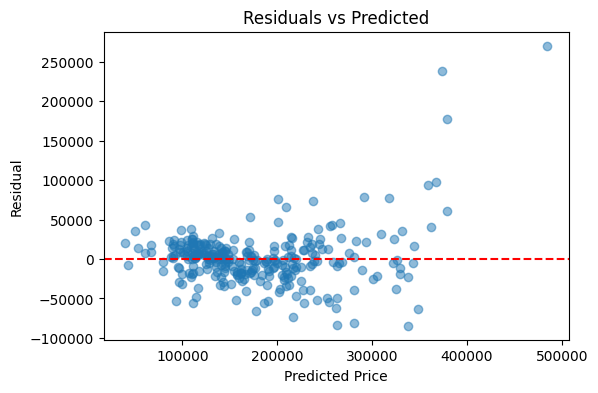

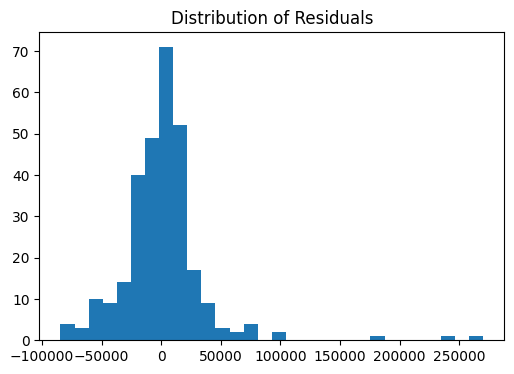

            MAE           MSE          RMSE        R2
0  21725.544374  1.278378e+09  35754.408168  0.833335


In [37]:
#part 5
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

residuals = y_test - y_pred

plt.figure(figsize=(6,4))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Price'); plt.ylabel('Residual')
plt.title('Residuals vs Predicted')
plt.show()

plt.figure(figsize=(6,4))
plt.hist(residuals, bins=30)
plt.title('Distribution of Residuals')
plt.show()

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(pd.DataFrame({'MAE':[mae],'MSE':[mse],'RMSE':[rmse],'R2':[r2]}))

Residual pattern: Mostly clustered around 0, but long right tail (outliers up to +250,000). Model underestimates price for some expensive houses — not fully random, slight systematic bias on high-end homes.

Metrics:

Metric	Value
MAE	$21,725.54
MSE	1.28 × 10⁹
RMSE	$35,754.41
R²	0.8333

What they mean:

MAE: avg error ~$21,726 per house
MSE: squares errors, punishes big mistakes more, not intuitive in raw units
RMSE: $35,754 — higher than MAE, confirms some large errors exist
R²: model explains 83.3% of price variance — solid fit
Best for non-technical stakeholder: MAE — simplest to explain

In [38]:
#part 6
train_pred = model.predict(X_train)

train_mae = mean_absolute_error(y_train, train_pred)
train_mse = mean_squared_error(y_train, train_pred)
train_rmse = np.sqrt(train_mse)
train_r2 = r2_score(y_train, train_pred)

comparison_metrics = pd.DataFrame({
    'Metric': ['MAE','MSE','RMSE','R2'],
    'Train': [train_mae, train_mse, train_rmse, train_r2],
    'Test':  [mae, mse, rmse, r2]
})
print(comparison_metrics)

  Metric         Train          Test
0    MAE  2.116505e+04  2.172554e+04
1    MSE  1.104517e+09  1.278378e+09
2   RMSE  3.323428e+04  3.575441e+04
3     R2  8.148197e-01  8.333346e-01


Gap between train and test is very small — errors are close, and test R² (0.8333) is actually slightly higher than train R² (0.8148). This means there's no overfitting — the model generalizes well to unseen data. Makes sense given the modest feature set (~10–12 features) and simple linear regression, which has limited capacity to overfit compared to more complex models.


#part 7

Most influential features:
Rank by coefficient magnitude, but caveat: a feature like GrLivArea (measured in hundreds/thousands of square feet) will naturally have a smaller raw coefficient than a binary neighborhood dummy, even if its real-world impact is larger, because the scale of the feature affects the coefficient's size. To compare fairly, either standardize features first or reason about total contribution (coefficient × typical value range) rather than the raw coefficient alone. Based on that, features like OverallQual, GrLivArea, and TotalBsmtSF typically dominate in this dataset.

Final interpretation:
The model explains a substantial portion of price variation (R² ≈ 0.8333 on the test set), meaning it captures major pricing drivers reasonably well, though it is not perfectly accurate. RMSE of roughly $35,754 indicates typical prediction error in real dollar terms, which is more interpretable for stakeholders than R² alone. Overall quality and living area emerge as the strongest predictors, consistent with real-world intuition. Linear Regression is limited here because it assumes purely additive, linear relationships between features and price, and cannot capture interactions (e.g., quality mattering more in certain neighborhoods) or nonlinear effects (e.g., diminishing returns on extra square footage). It's also sensitive to outliers and the limited feature subset used. Next steps would include trying regularized regression (Ridge/Lasso), tree-based models (Random Forest, Gradient Boosting), and incorporating more of the 79 available features with proper feature engineering.

In [39]:

test_df = pd.read_csv('test.csv')
test_ids = test_df['Id']

test_data = test_df[features].copy()
test_data['TotalBsmtSF'] = test_data['TotalBsmtSF'].fillna(data['TotalBsmtSF'].median())
test_data['GarageCars'] = test_data['GarageCars'].fillna(0)
test_data['KitchenQual'] = test_data['KitchenQual'].map(qual_map).fillna(3)  # fill unseen NA with 'TA'

test_data = pd.get_dummies(test_data, columns=['Neighborhood','HouseStyle'], drop_first=True)
# align columns with training set (important! test may be missing some dummy columns)
test_data = test_data.reindex(columns=X.columns, fill_value=0)

test_predictions = model.predict(test_data)

submission = pd.DataFrame({'Id': test_ids, 'SalePrice': test_predictions})
submission.to_csv('submission.csv', index=False)